# 02 · Exploratory Data Analysis (EDA)

**Goal:** understand *who* leaves and *why*, before building any model.

Questions we answer:
1. How many customers leave?
2. Do monthly-contract customers leave more than yearly ones?
3. Does time with the company (tenure) matter?
4. Does price matter?
5. Which services keep customers (the "hooks")?
6. Does payment method matter?
7. Who are the customers (age, family)?
8. Which **combinations** are the most dangerous?
9. How much money are we losing, and where?

> Run `01_data_types.ipynb` first. It creates `telco_clean.pkl`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the clean data made in notebook 01
df = pd.read_pickle("telco_clean.pkl")

print("Customers:", len(df))
df.head()

Customers: 7043


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,No,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,5575-GNVDE,Male,No,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,3668-QPYBK,Male,No,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,7795-CFOCW,Male,No,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,9237-HQITU,Female,No,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


## 1 · How many customers leave?

`Churn` is 1 if the customer left and 0 if they stayed.

Churn
0    5174
1    1869
Name: count, dtype: int64
Overall churn rate: 26.5%


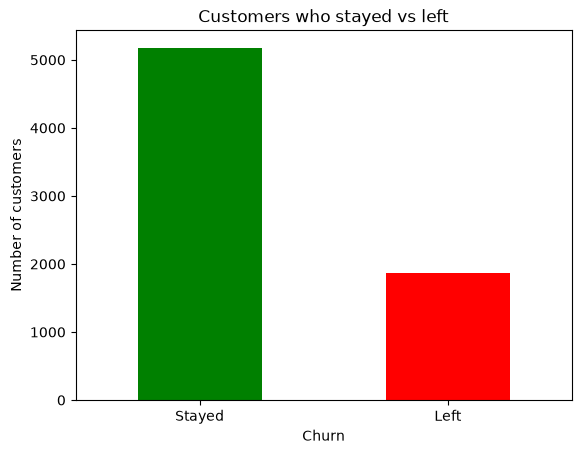

In [2]:
counts = df["Churn"].value_counts()
print(counts)

overall_churn = df["Churn"].mean() * 100   # mean of 0/1 = share of 1s
print(f"Overall churn rate: {overall_churn:.1f}%")

counts.plot(kind="bar", color=["green", "red"])
plt.xticks([0, 1], ["Stayed", "Left"], rotation=0)
plt.title("Customers who stayed vs left")
plt.ylabel("Number of customers")
plt.show()

**Note:** about 1 in 4 customers leaves. The data is *imbalanced* (more stayers than leavers). We must remember this when building the model.

## A small helper function

We will ask the same question many times: *"for each group in this column, what % of customers left?"*
So we write it once as a function.

How it works:
- `groupby(column)` splits customers into groups (e.g. Month-to-month / One year / Two year)
- `["Churn"].mean() * 100` gives the % who left in each group
- the red dashed line is the overall churn rate, so we can see which groups are above or below average

In [3]:
def churn_by(column):
    # % of customers who left, for each group in the column
    table = df.groupby(column, observed=True)["Churn"].agg(["count", "mean"])
    table.columns = ["customers", "churn_%"]
    table["churn_%"] = (table["churn_%"] * 100).round(1)
    table = table.sort_values("churn_%", ascending=False)

    # bar chart
    table["churn_%"].plot(kind="bar", color="steelblue")
    plt.axhline(overall_churn, color="red", linestyle="--", label="overall churn")
    plt.title(f"Churn % by {column}")
    plt.ylabel("% of customers who left")
    plt.xticks(rotation=30, ha="right")
    plt.legend()
    plt.show()

    return table

## 2 · Contract type: monthly vs yearly

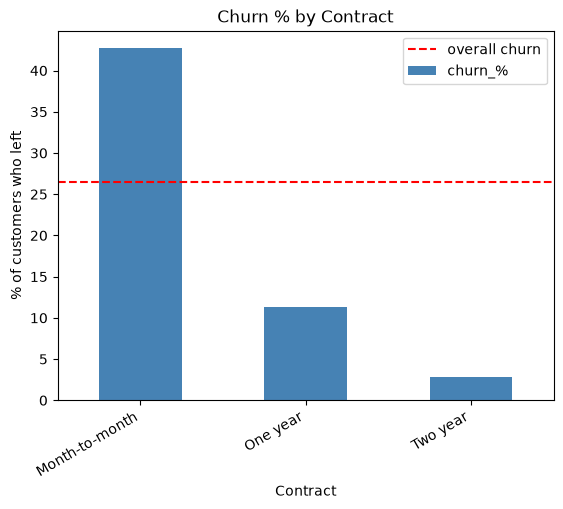

,customers,churn_%
Contract,,
Month-to-month,3875,42.7
One year,1473,11.3
Two year,1695,2.8


In [4]:
churn_by("Contract")

## 3 · Tenure: how long they have been with us

First, compare the tenure of customers who left vs stayed.

Average tenure (months)  left: 18.0 | stayed: 37.6


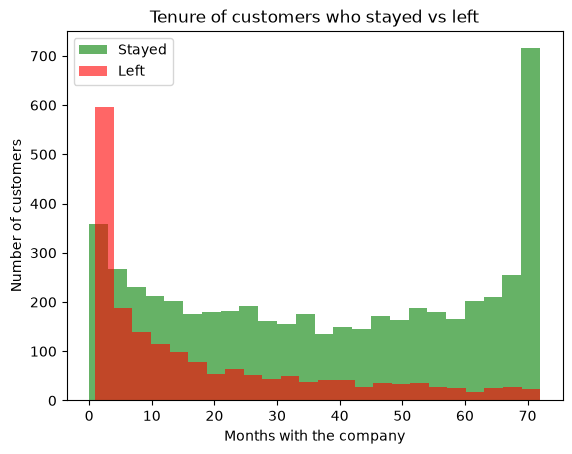

In [5]:
left = df[df["Churn"] == 1]
stayed = df[df["Churn"] == 0]

print("Average tenure (months)  left:", round(left["tenure"].mean(), 1),
      "| stayed:", round(stayed["tenure"].mean(), 1))

plt.hist(stayed["tenure"], bins=24, alpha=0.6, label="Stayed", color="green")
plt.hist(left["tenure"], bins=24, alpha=0.6, label="Left", color="red")
plt.title("Tenure of customers who stayed vs left")
plt.xlabel("Months with the company")
plt.ylabel("Number of customers")
plt.legend()
plt.show()

Now group tenure into bands (`pd.cut` puts each number into a range) and check churn per band.

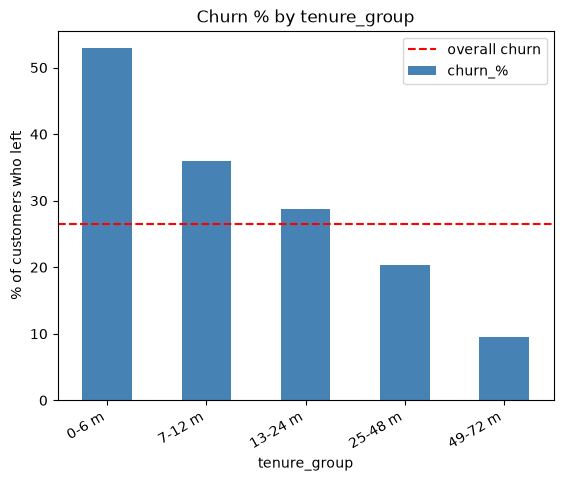

,customers,churn_%
tenure_group,,
0-6 m,1481,52.9
7-12 m,705,35.9
13-24 m,1024,28.7
25-48 m,1594,20.4
49-72 m,2239,9.5


In [6]:
df["tenure_group"] = pd.cut(df["tenure"],
                            bins=[-1, 6, 12, 24, 48, 72],
                            labels=["0-6 m", "7-12 m", "13-24 m", "25-48 m", "49-72 m"])
churn_by("tenure_group")

## 4 · Price: does paying more make people leave?

Average monthly charge  left: $ 74.44 | stayed: $ 61.27


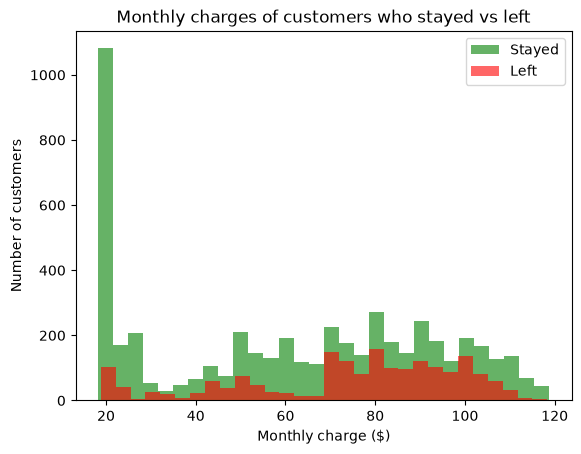

In [7]:
print("Average monthly charge  left: $", round(left["MonthlyCharges"].mean(), 2),
      "| stayed: $", round(stayed["MonthlyCharges"].mean(), 2))

plt.hist(stayed["MonthlyCharges"], bins=30, alpha=0.6, label="Stayed", color="green")
plt.hist(left["MonthlyCharges"], bins=30, alpha=0.6, label="Left", color="red")
plt.title("Monthly charges of customers who stayed vs left")
plt.xlabel("Monthly charge ($)")
plt.ylabel("Number of customers")
plt.legend()
plt.show()

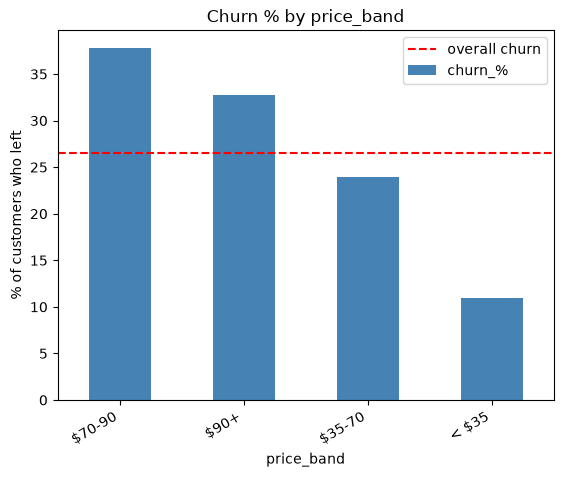

,customers,churn_%
price_band,,
$70-90,1844,37.8
$90+,1739,32.8
$35-70,1725,23.9
< $35,1735,10.9


In [8]:
df["price_band"] = pd.cut(df["MonthlyCharges"],
                          bins=[0, 35, 70, 90, 120],
                          labels=["< $35", "$35-70", "$70-90", "$90+"])
churn_by("price_band")

## 5 · Services: what hooks customers?

### Internet type

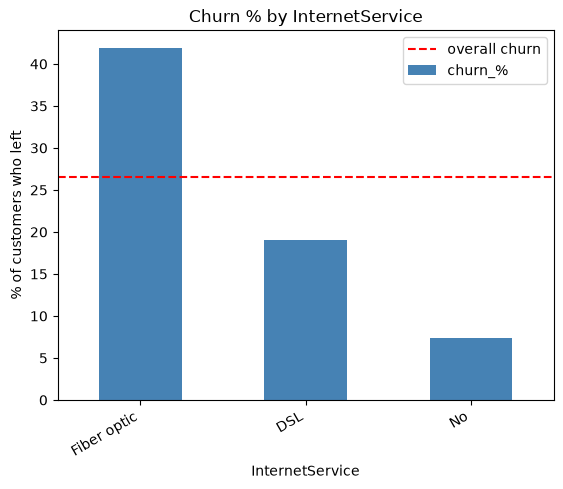

,customers,churn_%
InternetService,,
Fiber optic,3096,41.9
DSL,2421,19.0
No,1526,7.4


In [9]:
churn_by("InternetService")

Fiber is the premium (most expensive) product, so why do its customers leave so much? Let's check what fiber customers pay.

In [10]:
df.groupby("InternetService", observed=True)["MonthlyCharges"].mean().round(2)

InternetService
DSL            58.10
Fiber optic    91.50
No             21.08
Name: MonthlyCharges, dtype: float64

### Add-on services

For each add-on, compare churn for customers who **have** it vs **don't have** it.
We only look at internet customers (the others can't have these add-ons).

In [11]:
addons = ["OnlineSecurity", "OnlineBackup", "DeviceProtection",
          "TechSupport", "StreamingTV", "StreamingMovies"]

internet_users = df[df["InternetService"] != "No"]

rows = []
for addon in addons:
    with_it = internet_users[internet_users[addon] == "Yes"]["Churn"].mean() * 100
    without_it = internet_users[internet_users[addon] == "No"]["Churn"].mean() * 100
    rows.append([addon, round(with_it, 1), round(without_it, 1)])

addon_table = pd.DataFrame(rows, columns=["add-on", "churn_%_with", "churn_%_without"])
addon_table["difference"] = addon_table["churn_%_without"] - addon_table["churn_%_with"]
addon_table = addon_table.sort_values("difference", ascending=False)
addon_table

,add-on,churn_%_with,churn_%_without,difference
0,OnlineSecurity,14.6,41.8,27.2
3,TechSupport,15.2,41.6,26.4
1,OnlineBackup,21.5,39.9,18.4
2,DeviceProtection,22.5,39.1,16.6
5,StreamingMovies,29.9,33.7,3.8
4,StreamingTV,30.1,33.5,3.4


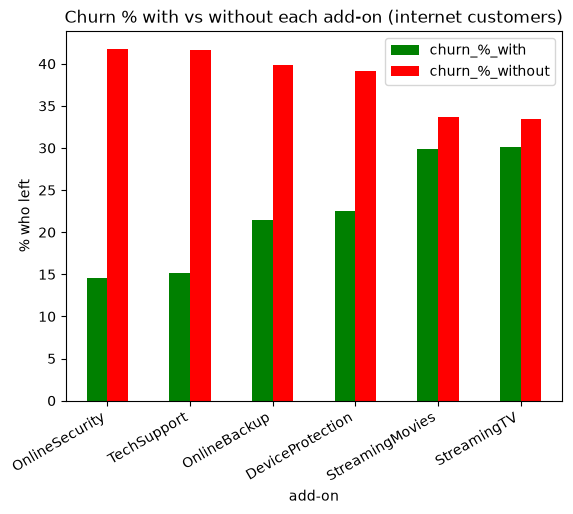

In [12]:
addon_table.plot(x="add-on", y=["churn_%_with", "churn_%_without"],
                 kind="bar", color=["green", "red"])
plt.title("Churn % with vs without each add-on (internet customers)")
plt.ylabel("% who left")
plt.xticks(rotation=30, ha="right")
plt.show()

### Number of add-ons

Does having *more* services keep people? We count how many of the 6 add-ons each customer has.

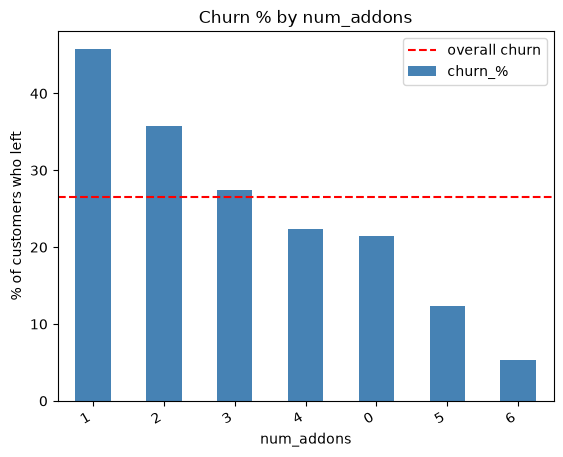

,customers,churn_%
num_addons,,
1,966,45.8
2,1033,35.8
3,1118,27.4
4,852,22.3
0,2219,21.4
5,571,12.4
6,284,5.3


In [13]:
df["num_addons"] = (df[addons] == "Yes").sum(axis=1)
churn_by("num_addons")

## 6 · Payment and billing

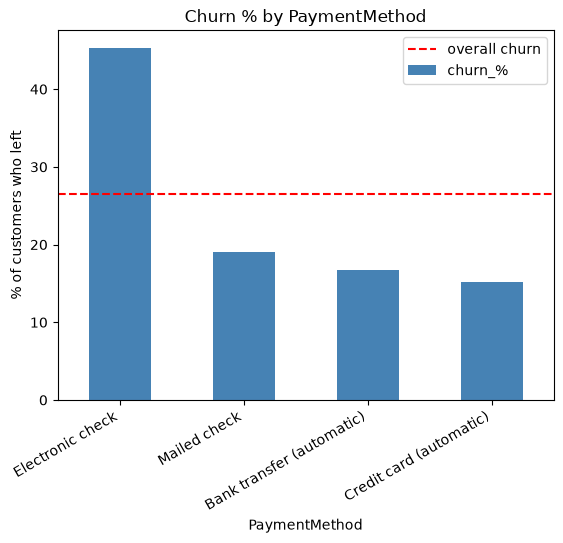

,customers,churn_%
PaymentMethod,,
Electronic check,2365,45.3
Mailed check,1612,19.1
Bank transfer (automatic),1544,16.7
Credit card (automatic),1522,15.2


In [14]:
churn_by("PaymentMethod")

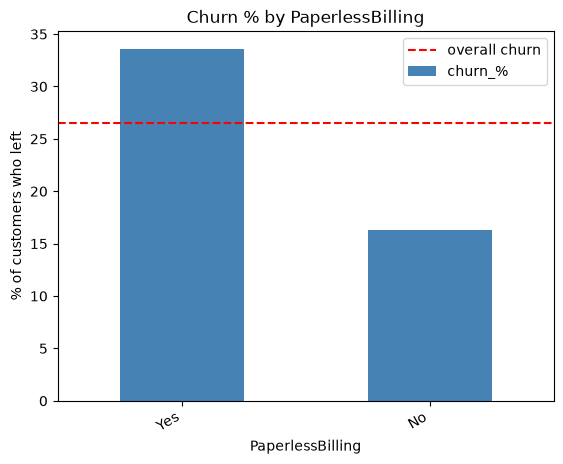

,customers,churn_%
PaperlessBilling,,
Yes,4171,33.6
No,2872,16.3


In [15]:
churn_by("PaperlessBilling")

## 7 · Who are the customers?

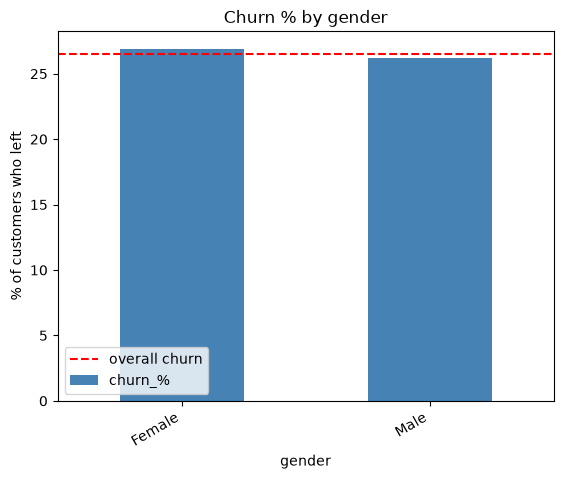

        customers  churn_%
gender                    
Female       3488     26.9
Male         3555     26.2 



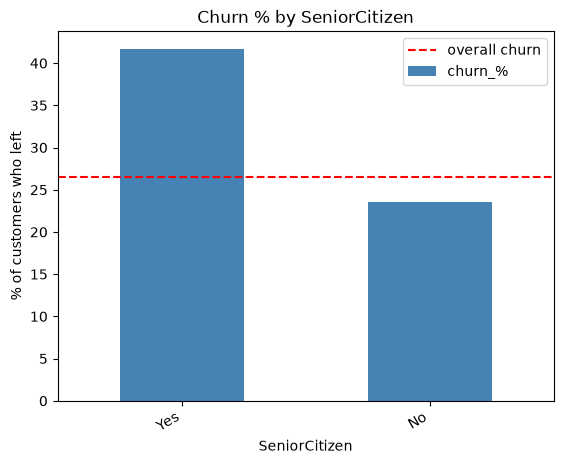

               customers  churn_%
SeniorCitizen                    
Yes                 1142     41.7
No                  5901     23.6 



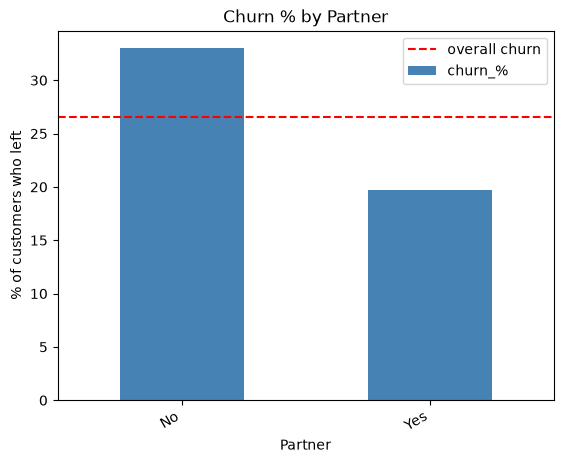

         customers  churn_%
Partner                    
No            3641     33.0
Yes           3402     19.7 



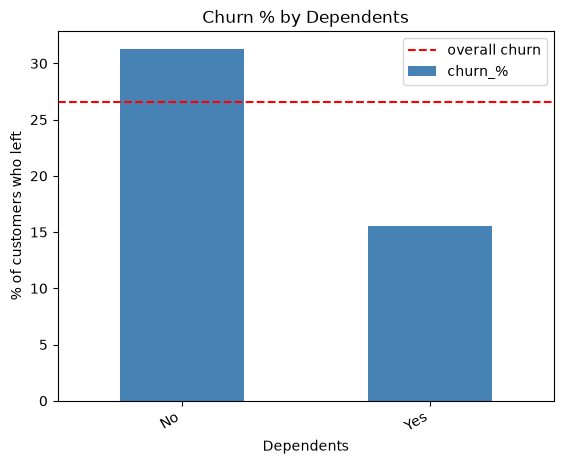

            customers  churn_%
Dependents                    
No               4933     31.3
Yes              2110     15.5 



In [16]:
for col in ["gender", "SeniorCitizen", "Partner", "Dependents"]:
    print(churn_by(col), "\n")

## 8 · Dangerous combinations

One column at a time hides the full story. Here we cross **contract** with **internet type**.
`pivot_table` makes a grid: rows = contract, columns = internet type, cells = churn %.

In [17]:
grid = df.pivot_table(index="Contract", columns="InternetService",
                      values="Churn", aggfunc="mean", observed=True) * 100
grid = grid.round(1)
grid

InternetService,DSL,Fiber optic,No
Contract,,,
Month-to-month,32.2,54.6,18.9
One year,9.3,19.3,2.5
Two year,1.9,7.2,0.8


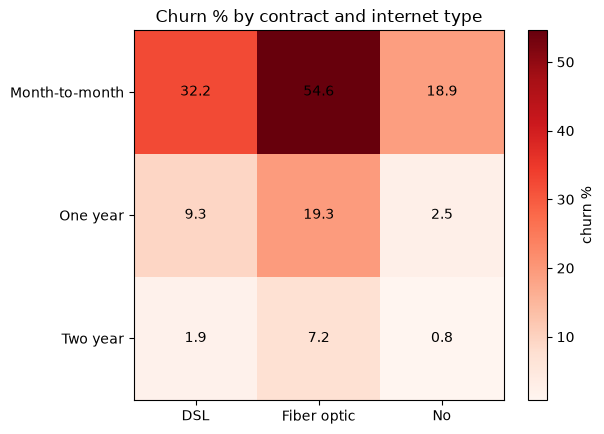

In [18]:
plt.imshow(grid, cmap="Reds")
plt.colorbar(label="churn %")
plt.xticks(range(len(grid.columns)), grid.columns)
plt.yticks(range(len(grid.index)), grid.index)
for i in range(len(grid.index)):
    for j in range(len(grid.columns)):
        plt.text(j, i, grid.iloc[i, j], ha="center", va="center")
plt.title("Churn % by contract and internet type")
plt.show()

Same idea for **contract × tenure group**: are new monthly customers the worst?

In [19]:
grid2 = df.pivot_table(index="Contract", columns="tenure_group",
                       values="Churn", aggfunc="mean", observed=True) * 100
grid2.round(1)

tenure_group,0-6 m,7-12 m,13-24 m,25-48 m,49-72 m
Contract,,,,,
Month-to-month,55.2,42.0,37.7,32.9,26.0
One year,10.3,10.6,8.1,10.6,12.9
Two year,0.0,0.0,0.0,2.2,3.3


## 9 · How much money are we losing?

Each churned customer takes their `MonthlyCharges` with them, every month.

In [20]:
lost_per_month = left["MonthlyCharges"].sum()
total_per_month = df["MonthlyCharges"].sum()

print(f"Monthly revenue lost to churn: ${lost_per_month:,.0f}")
print(f"Yearly revenue lost to churn:  ${lost_per_month * 12:,.0f}")
print(f"Share of all monthly revenue:  {lost_per_month / total_per_month * 100:.1f}%")

Monthly revenue lost to churn: $139,131
Yearly revenue lost to churn:  $1,669,570
Share of all monthly revenue:  30.5%


Where does the lost money come from?

In [21]:
lost_by_contract = left.groupby("Contract", observed=True)["MonthlyCharges"].sum()
(lost_by_contract / lost_by_contract.sum() * 100).round(1)

Contract
Month-to-month    86.9
One year          10.1
Two year           3.0
Name: MonthlyCharges, dtype: float64

In [22]:
lost_by_internet = left.groupby("InternetService", observed=True)["MonthlyCharges"].sum()
(lost_by_internet / lost_by_internet.sum() * 100).round(1)

InternetService
DSL            16.2
Fiber optic    82.2
No              1.7
Name: MonthlyCharges, dtype: float64

## 10 · Ranking: which groups leave the most?

We check every group in every column and list the riskiest ones.

In [23]:
columns_to_check = ["Contract", "tenure_group", "price_band", "InternetService",
                    "OnlineSecurity", "TechSupport", "PaymentMethod",
                    "PaperlessBilling", "SeniorCitizen", "Partner", "Dependents"]

rows = []
for col in columns_to_check:
    for group, part in df.groupby(col, observed=True):
        rows.append([col, group, len(part), round(part["Churn"].mean() * 100, 1)])

ranking = pd.DataFrame(rows, columns=["column", "group", "customers", "churn_%"])
ranking.sort_values("churn_%", ascending=False).head(12)

,column,group,customers,churn_%
3,tenure_group,0-6 m,1481,52.9
23,PaymentMethod,Electronic check,2365,45.3
0,Contract,Month-to-month,3875,42.7
13,InternetService,Fiber optic,3096,41.9
15,OnlineSecurity,No,3498,41.8
28,SeniorCitizen,Yes,1142,41.7
18,TechSupport,No,3473,41.6
10,price_band,$70-90,1844,37.8
4,tenure_group,7-12 m,705,35.9
26,PaperlessBilling,Yes,4171,33.6


And the safest groups (most loyal):

In [24]:
ranking.sort_values("churn_%").head(8)

,column,group,customers,churn_%
2,Contract,Two year,1695,2.8
14,InternetService,No,1526,7.4
19,TechSupport,No internet service,1526,7.4
16,OnlineSecurity,No internet service,1526,7.4
7,tenure_group,49-72 m,2239,9.5
8,price_band,< $35,1735,10.9
1,Contract,One year,1473,11.3
17,OnlineSecurity,Yes,2019,14.6


## Key findings

| # | Question | Finding |
|---|---|---|
| 1 | How many leave? | **26.5%** (1,869 of 7,043). Imbalanced data. |
| 2 | Monthly vs yearly? | **Month-to-month 42.7%** vs one-year 11.3% vs two-year 2.8%. Monthly customers are ~15x riskier than two-year ones. |
| 3 | Tenure? | Leavers stayed **18 months** on average vs **37.6** for stayers. **First 6 months: 52.9% churn.** Risk falls steadily with time. |
| 4 | Price? | Leavers pay **$74** vs **$61**. Churn peaks in the **$70-90** band (37.8%). |
| 5 | Hooks? | **OnlineSecurity** and **TechSupport** cut churn from ~42% to ~15%. Backup/protection help less, streaming barely matters. More add-ons = more loyal (6 add-ons: 5.3%). *(The 0-add-on group looks low only because it includes customers with no internet.)* |
| 6 | Payment? | **Electronic check 45.3%** vs ~15-19% for the others. Automatic payments are the stickiest. |
| 7 | Who? | **Seniors 41.7%**, single customers 33%, no dependents 31.3%. Gender makes no difference. |
| 8 | Combinations? | **Fiber + month-to-month = 54.6%**. **Month-to-month + first 6 months = 55.2%**. Two-year contracts almost never churn in year 1-2. |
| 9 | Money? | **$139K/month, about $1.67M/year, 30.5% of revenue** lost. **87%** of lost revenue is month-to-month; **82%** is fiber. |

### Typical churner
A **new** (under 1 year) customer on a **month-to-month** contract with **fiber internet**, paying **$70-90+**, **without OnlineSecurity or TechSupport**, and paying by **electronic check**.

### What this means for retention
- **Lock in:** move month-to-month customers to 1-year contracts (biggest lever)
- **Hook:** bundle free OnlineSecurity and TechSupport trials, especially for fiber customers
- **Onboard:** focus on the first 6 months
- **Autopay:** push electronic-check payers to automatic payment
- **Fix fiber value:** fiber costs ~$91/month and loses 42% of customers, a price-vs-value problem to explore in the pricing simulation

> These are *correlations*, not proof of cause. The model (next notebook) checks which factors still matter when all are considered together.
